# RecruitGen — Model 1 of 3: Autoencoder (Resume Image Denoising)

**Goal:** remove noise from scanned / low-quality resume images so the text becomes reliably readable.

```
Noisy Image → Encoder → Latent Space → Decoder → Denoised Resume
```

**Training concept:** input = noisy resume, target = clean resume.
**Metrics:** MSE, PSNR, SSIM, visual comparison. **Regularisation:** Early Stopping.

**Outputs:** `encoder.h5` and `decoder.h5` (used by the Streamlit app).

## 1. Setup

In [1]:
import os, glob, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont, ImageFilter

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
import keras
from keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = 256          # model works on 256x256 grayscale tiles
QUICK_RUN = False       # True = tiny run to test the notebook end-to-end
FAST_RUN = True         # True = CPU-friendly reduced budget (~10 min); False = original full recipe (GPU recommended)
NUM_PAGES = 12 if QUICK_RUN else (40 if FAST_RUN else 160)
PATCHES_PER_PAGE = 4 if QUICK_RUN else (10 if FAST_RUN else 24)
EPOCHS = 1 if QUICK_RUN else (6 if FAST_RUN else 60)
BATCH_SIZE = 16

DATA_DIR = "data/clean_resumes"   # optional: put your own clean resume images here
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

I0000 00:00:1792753873.109132     829 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792753874.421734     829 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1


## 2. Dataset — clean resume pages + synthetic noise

If `data/clean_resumes/` contains clean resume/document images they are used directly.
Otherwise realistic resume-like pages are rendered (name, headings, bullet points, two-column blocks).
Noisy versions are created with gaussian noise, salt & pepper, coffee stains, blur and scan shadows.

### Optional: real clean resume pages from Kaggle

**Kaggle Resume Dataset:** https://www.kaggle.com/datasets/snehaanbhawal/resume-dataset

`Resume/Resume.csv` (`ID`, `Resume_str`, `Resume_html`, `Category` — 2,484 resumes, 24 categories) and
`data/data/<CATEGORY>/<ID>.pdf` (the same resumes as PDFs). Setup — pick one:

1. **Automatic:** the optional cell below calls `kagglehub.dataset_download("snehaanbhawal/resume-dataset")`
   (`pip install kagglehub`; add `~/.kaggle/kaggle.json` if Kaggle asks for authentication).
2. **Manual:** download the ZIP from the link and extract it to `RecruitGen/data/kaggle_resume/`.
3. **Kaggle CLI:** `kaggle datasets download -d snehaanbhawal/resume-dataset -p data/kaggle_resume --unzip` (run in `RecruitGen/`)

The PDFs are real, clean resume pages. Set `USE_KAGGLE_PDFS = True` to render the first page of
`KAGGLE_PAGES` random PDFs into `data/clean_resumes/` — the dataset cell below then uses them instead of rendered pages.
Default `False` reproduces the shipped `encoder.h5` / `decoder.h5` recipe.

In [2]:
USE_KAGGLE_PDFS = False
KAGGLE_PAGES = 12 if QUICK_RUN else 160

if USE_KAGGLE_PDFS:
    import fitz, kagglehub                                   # PyMuPDF (in requirements.txt), kagglehub
    kaggle_root = kagglehub.dataset_download("snehaanbhawal/resume-dataset")
    pdfs = sorted(glob.glob(os.path.join(kaggle_root, "data", "data", "*", "*.pdf")))
    random.shuffle(pdfs)
    os.makedirs(DATA_DIR, exist_ok=True)
    for i, pdf_path in enumerate(pdfs[:KAGGLE_PAGES]):
        with fitz.open(pdf_path) as doc:
            doc[0].get_pixmap(dpi=150, colorspace=fitz.csGRAY).save(os.path.join(DATA_DIR, f"kaggle_{i:04d}.png"))
    print(f"{len(pdfs)} Kaggle PDFs found -> {min(len(pdfs), KAGGLE_PAGES)} clean pages written to {DATA_DIR}")

In [3]:
WORDS = ("python java sql tensorflow pytorch aws azure docker kubernetes data analysis machine learning "
         "communication leadership project management engineer developer analyst cloud deployment "
         "university bachelor master certification experience responsible designed implemented improved "
         "pipeline dashboard model accuracy customers team agile api backend frontend testing").split()
HEADINGS = ["PROFESSIONAL SUMMARY", "EXPERIENCE", "EDUCATION", "SKILLS", "PROJECTS", "CERTIFICATIONS"]

def _font(size):
    for name in ["arial.ttf", "DejaVuSans.ttf", "LiberationSans-Regular.ttf"]:
        try:
            return ImageFont.truetype(name, size)
        except OSError:
            continue
    return ImageFont.load_default()

def render_resume_page(w=1240, h=1754):
    img = Image.new("L", (w, h), 255)
    d = ImageDraw.Draw(img)
    y = 70
    d.text((80, y), " ".join(random.sample(WORDS, 2)).upper(), fill=0, font=_font(54)); y += 80
    d.text((80, y), " | ".join(random.sample(WORDS, 3)), fill=60, font=_font(24)); y += 60
    while y < h - 120:
        d.text((80, y), random.choice(HEADINGS), fill=0, font=_font(30)); y += 44
        d.line((80, y, w - 80, y), fill=90, width=2); y += 16
        for _ in range(random.randint(3, 7)):
            line = " ".join(random.choices(WORDS, k=random.randint(6, 12))).capitalize()
            d.text((100, y), "• " + line, fill=20, font=_font(random.choice([20, 22, 24]))); y += 34
        y += 24
    return img

def add_scan_noise(img):
    arr = np.asarray(img, dtype=np.float32) / 255.0
    h, w = arr.shape
    noisy = arr + np.random.normal(0, random.uniform(0.04, 0.15), arr.shape)
    m = np.random.rand(h, w)
    sp = random.uniform(0.005, 0.03)
    noisy[m < sp / 2] = 0.0
    noisy[m > 1 - sp / 2] = 1.0
    yy, xx = np.mgrid[0:h, 0:w]
    for _ in range(random.randint(1, 4)):          # stains
        cy, cx, r = random.randint(0, h), random.randint(0, w), random.randint(40, 260)
        noisy -= np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * r ** 2)) * random.uniform(0.1, 0.35)
    noisy -= np.linspace(0, random.uniform(0, 0.25), w)[None, :]   # scan shadow
    out = Image.fromarray((np.clip(noisy, 0, 1) * 255).astype(np.uint8))
    if random.random() < 0.4:
        out = out.filter(ImageFilter.GaussianBlur(random.uniform(0.4, 1.0)))
    return out

def load_clean_pages():
    files = sorted(glob.glob(os.path.join(DATA_DIR, "*.*")))
    if files:
        print(f"Using {len(files)} clean images from {DATA_DIR}")
        return [Image.open(f).convert("L") for f in files]
    print(f"Rendering {NUM_PAGES} synthetic resume pages")
    return [render_resume_page() for _ in range(NUM_PAGES)]

def make_patches(pages):
    X, Y = [], []
    for page in pages:
        noisy = add_scan_noise(page)
        c, n = np.asarray(page, np.float32) / 255.0, np.asarray(noisy, np.float32) / 255.0
        h, w = c.shape
        for _ in range(PATCHES_PER_PAGE):
            y, x = random.randint(0, h - IMG_SIZE), random.randint(0, w - IMG_SIZE)
            X.append(n[y:y + IMG_SIZE, x:x + IMG_SIZE]); Y.append(c[y:y + IMG_SIZE, x:x + IMG_SIZE])
    return np.array(X)[..., None], np.array(Y)[..., None]

pages = load_clean_pages()
X, Y = make_patches(pages)
idx = np.random.permutation(len(X))
X, Y = X[idx], Y[idx]
n_val, n_test = int(0.15 * len(X)), int(0.10 * len(X))
X_test, Y_test = X[:n_test], Y[:n_test]
X_val, Y_val = X[n_test:n_test + n_val], Y[n_test:n_test + n_val]
X_train, Y_train = X[n_test + n_val:], Y[n_test + n_val:]
print("train", X_train.shape, "| val", X_val.shape, "| test", X_test.shape)

Rendering 40 synthetic resume pages


train (300, 256, 256, 1) | val (60, 256, 256, 1) | test (40, 256, 256, 1)


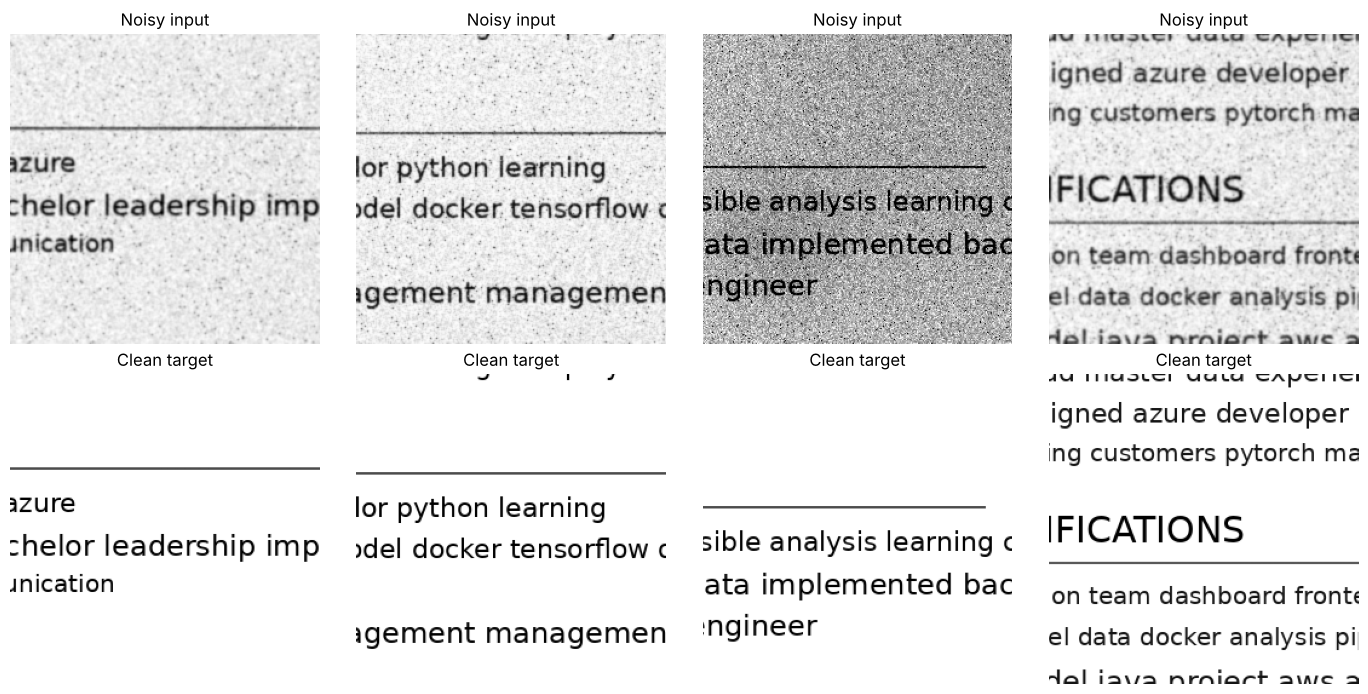

In [4]:
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    ax[0, i].imshow(X_train[i, ..., 0], cmap="gray"); ax[0, i].set_title("Noisy input"); ax[0, i].axis("off")
    ax[1, i].imshow(Y_train[i, ..., 0], cmap="gray"); ax[1, i].set_title("Clean target"); ax[1, i].axis("off")
plt.tight_layout(); plt.show()

## 3. Model — convolutional Encoder → Latent Space → Decoder

U-Net style autoencoder: the encoder compresses the 256×256 tile into a **32×32×256 latent space**;
the decoder reconstructs the clean tile. Skip connections keep thin text strokes sharp.

In [5]:
def conv(x, filters, name):
    return layers.Conv2D(filters, 3, padding="same", activation="relu", name=name)(x)

inp = keras.Input((IMG_SIZE, IMG_SIZE, 1), name="dirty_resume")
# ---------------- Encoder ----------------
e1 = conv(conv(inp, 32, "enc1_a"), 32, "enc1_b")                       # 256x256x32
e2 = conv(conv(layers.MaxPooling2D(name="pool1")(e1), 64, "enc2_a"), 64, "enc2_b")    # 128x128x64
e3 = conv(conv(layers.MaxPooling2D(name="pool2")(e2), 128, "enc3_a"), 128, "enc3_b")  # 64x64x128
latent = conv(layers.MaxPooling2D(name="pool3")(e3), 256, "latent_representation")  # 32x32x256
# ---------------- Decoder ----------------
d = conv(latent, 256, "dec_bottleneck")
d = layers.UpSampling2D(name="up1")(d); d = layers.Concatenate(name="skip1")([d, e3])
d = conv(conv(d, 128, "dec1_a"), 128, "dec1_b")
d = layers.UpSampling2D(name="up2")(d); d = layers.Concatenate(name="skip2")([d, e2])
d = conv(conv(d, 64, "dec2_a"), 64, "dec2_b")
d = layers.UpSampling2D(name="up3")(d); d = layers.Concatenate(name="skip3")([d, e1])
d = conv(conv(d, 32, "dec3_a"), 32, "dec3_b")
out = layers.Conv2D(1, 3, padding="same", activation="sigmoid", name="clean_resume")(d)

autoencoder = keras.Model(inp, out, name="Resume_Denoising_Autoencoder")

def psnr_metric(y_true, y_pred):
    return tf.reduce_mean(tf.image.psnr(y_true, y_pred, max_val=1.0))

def ssim_metric(y_true, y_pred):
    return tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))

autoencoder.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=[psnr_metric, ssim_metric])
autoencoder.summary()

Model: "Resume_Denoising_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ dirty_resume        │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_a (Conv2D)     │ (None, 256, 256,  │        320 │ dirty_resume[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_b (Conv2D)     │ (None, 256, 256,  │      9,248 │ enc1_a[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 128, 128,  │          0 │ enc1_b[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_a (Conv2D)     │ (None, 128, 128,  │     18,496 │ pool1[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_b (Conv2D)     │ (None, 128, 128,  │     36,928 │ enc2_a[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool2               │ (None, 64, 64,    │          0 │ enc2_b[0][0]      │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc3_a (Conv2D)     │ (None, 64, 64,    │     73,856 │ pool2[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc3_b (Conv2D)     │ (None, 64, 64,    │    147,584 │ enc3_a[0][0]      │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool3               │ (None, 32, 32,    │          0 │ enc3_b[0][0]      │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latent_representat… │ (None, 32, 32,    │    295,168 │ pool3[0][0]       │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_bottleneck      │ (None, 32, 32,    │    590,080 │ latent_represent… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up1 (UpSampling2D)  │ (None, 64, 64,    │          0 │ dec_bottleneck[0… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip1 (Concatenate) │ (None, 64, 64,    │          0 │ up1[0][0],        │
│                     │ 384)              │            │ enc3_b[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec1_a (Conv2D)     │ (None, 64, 64,    │    442,496 │ skip1[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec1_b (Conv2D)     │ (None, 64, 64,    │    147,584 │ dec1_a[0][0]      │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up2 (UpSampling2D)  │ (None, 128, 128,  │          0 │ dec1_b[0][0]    

 Total params: 1,946,561 (7.43 MB)

 Trainable params: 1,946,561 (7.43 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Training (with Early Stopping)

In [6]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint(os.path.join(OUTPUT_DIR, "ae_best.keras"), monitor="val_loss", save_best_only=True),
]
history = autoencoder.fit(
    X_train, Y_train, validation_data=(X_val, Y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, shuffle=True,
)

Epoch 1/6


E0000 00:00:1792753886.513916     829 util.cc:131] oneDNN supports DT_INT32 only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


 1/19 ━━━━━━━━━━━━━━━━━━━━ 1:52 6s/step - loss: 0.2296 - psnr_metric: 6.3910 - ssim_metric: 0.5085

 2/19 ━━━━━━━━━━━━━━━━━━━━ 1:00 4s/step - loss: 0.2172 - psnr_metric: 6.6396 - ssim_metric: 0.5097

 3/19 ━━━━━━━━━━━━━━━━━━━━ 55s 3s/step - loss: 0.1868 - psnr_metric: 7.4260 - ssim_metric: 0.5385 

 4/19 ━━━━━━━━━━━━━━━━━━━━ 51s 3s/step - loss: 0.1565 - psnr_metric: 8.5468 - ssim_metric: 0.5532

... (119 outputs left out)

18/19 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - loss: 0.0590 - psnr_metric: 12.6250 - ssim_metric: 0.6386

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - loss: 0.0590 - psnr_metric: 12.6190 - ssim_metric: 0.6388

19/19 ━━━━━━━━━━━━━━━━━━━━ 80s 4s/step - loss: 0.0590 - psnr_metric: 12.6190 - ssim_metric: 0.6388 - val_loss: 0.0584 - val_psnr_metric: 12.7062 - val_ssim_metric: 0.6445 - learning_rate: 5.0000e-04


Restoring model weights from the end of the best epoch: 1.


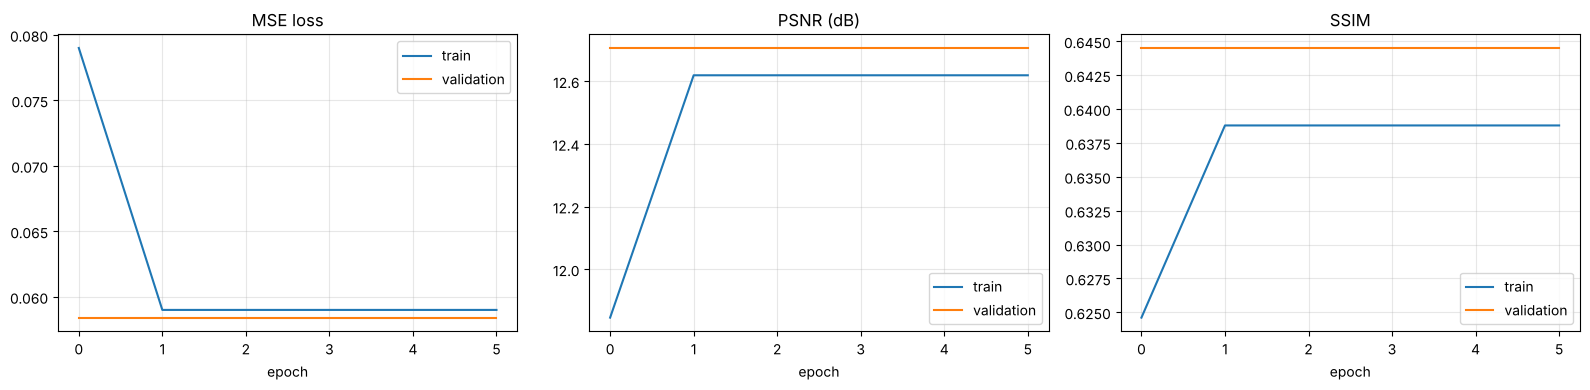

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, key, title in zip(ax, ["loss", "psnr_metric", "ssim_metric"], ["MSE loss", "PSNR (dB)", "SSIM"]):
    a.plot(history.history[key], label="train"); a.plot(history.history["val_" + key], label="validation")
    a.set_title(title); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Evaluation — MSE · PSNR · SSIM on the test set

In [8]:
pred = autoencoder.predict(X_test, batch_size=BATCH_SIZE, verbose=0)

def report(name, a, b):
    mse = float(np.mean((a - b) ** 2))
    psnr = float(tf.reduce_mean(tf.image.psnr(a, b, 1.0)))
    ssim = float(tf.reduce_mean(tf.image.ssim(a, b, 1.0)))
    print(f"{name:22s} MSE={mse:.5f}  PSNR={psnr:6.2f} dB  SSIM={ssim:.4f}")

report("Noisy vs clean", X_test, Y_test)
report("Denoised vs clean", pred, Y_test)

Noisy vs clean         MSE=0.03974  PSNR= 15.11 dB  SSIM=0.4394
Denoised vs clean      MSE=0.05537  PSNR= 13.20 dB  SSIM=0.6600


### Evaluation matrix — noisy input vs this run vs the shipped app model

All rows are scored on the **same held-out test patches**. *Shipped app model* = `models/autoencoder/encoder.h5` +
`decoder.h5` (the weights the Streamlit app uses; they are loaded, never overwritten). With `FAST_RUN = True` the
notebook model is trained on a reduced budget, so the shipped model is the reference for the app's quality.

In [9]:
import pandas as pd

def metrics_row(name, a, b):
    return {"comparison": name, "MSE": float(np.mean((a - b) ** 2)),
            "PSNR (dB)": float(tf.reduce_mean(tf.image.psnr(a, b, 1.0))),
            "SSIM": float(tf.reduce_mean(tf.image.ssim(a, b, 1.0)))}

app_encoder = keras.models.load_model("encoder.h5", compile=False)
app_decoder = keras.models.load_model("decoder.h5", compile=False)
app_pred = app_decoder.predict(app_encoder.predict(X_test, batch_size=BATCH_SIZE, verbose=0),
                               batch_size=BATCH_SIZE, verbose=0)

ae_metrics = pd.DataFrame([
    metrics_row("Noisy input (no model)", X_test, Y_test),
    metrics_row("Notebook model (this run)", pred, Y_test),
    metrics_row("Shipped app model (encoder.h5 + decoder.h5)", app_pred, Y_test),
]).set_index("comparison")
print(f"Test patches: {len(X_test)} · {'FAST_RUN' if FAST_RUN else 'full'} budget · {EPOCHS} max epochs")
ae_metrics.round(4)

Test patches: 40 · FAST_RUN budget · 6 max epochs


,MSE,PSNR (dB),SSIM
comparison,,,
Noisy input (no model),0.0397,15.1063,0.4394
Notebook model (this run),0.0554,13.1977,0.6600
Shipped app model (encoder.h5 + decoder.h5),0.0366,14.6754,0.4820


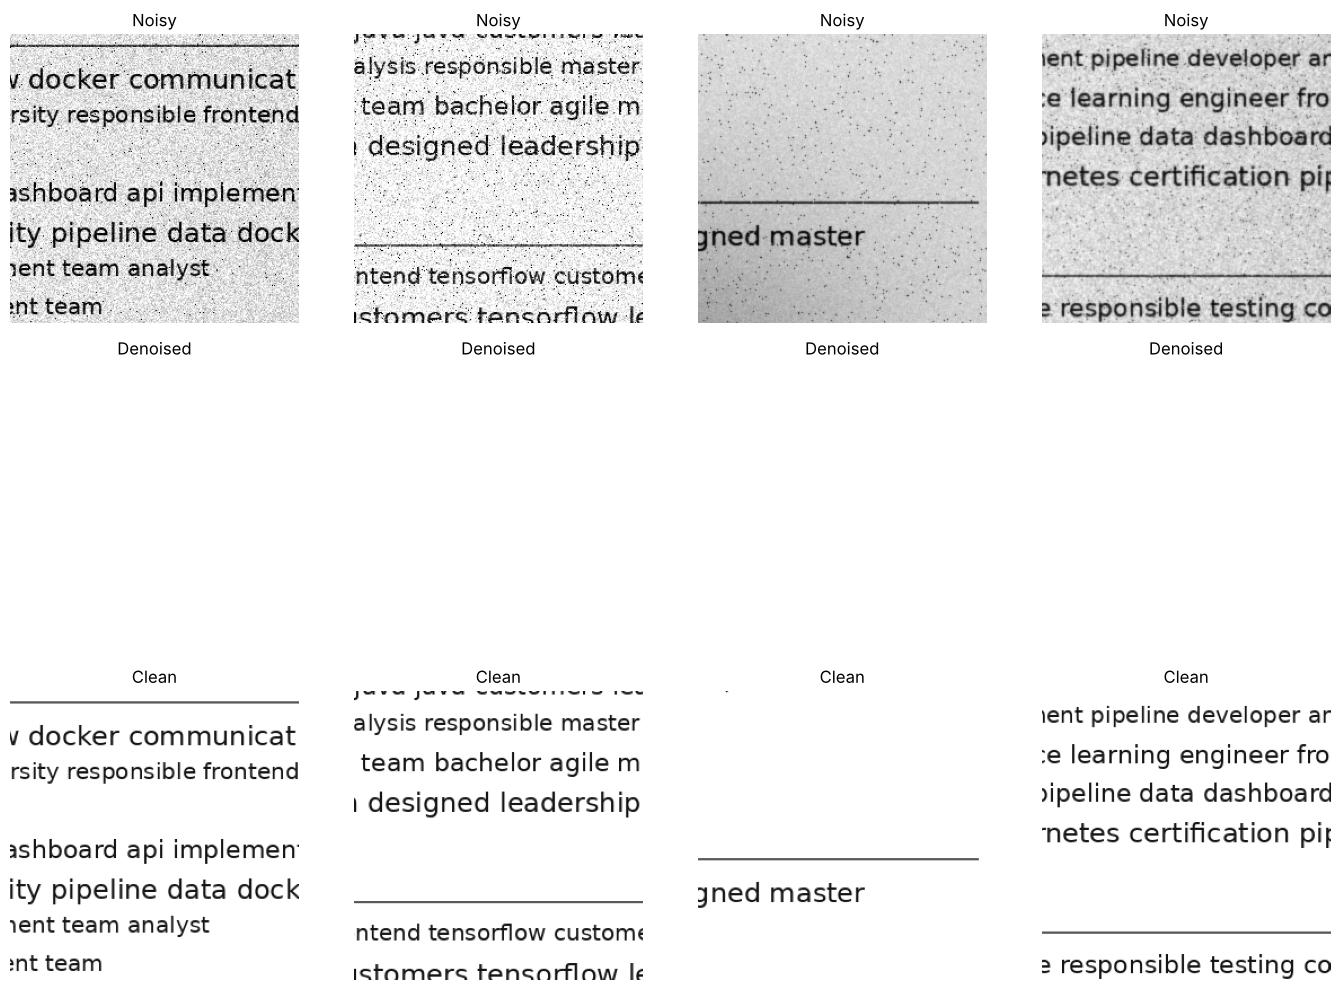

In [10]:
fig, ax = plt.subplots(3, 4, figsize=(14, 10))
for i in range(4):
    for r, (img, t) in enumerate([(X_test[i], "Noisy"), (pred[i], "Denoised"), (Y_test[i], "Clean")]):
        ax[r, i].imshow(img[..., 0], cmap="gray", vmin=0, vmax=1); ax[r, i].set_title(t); ax[r, i].axis("off")
plt.tight_layout(); plt.show()

## 6. Export — `encoder.h5` + `decoder.h5`

The encoder outputs the latent space plus the three skip feature maps; the decoder consumes them.
`decoder(encoder(x))` is identical to the full autoencoder.

In [11]:
g = autoencoder.get_layer
encoder = keras.Model(inp, [latent, e3, e2, e1], name="resume_encoder")

lat_in = keras.Input((32, 32, 256), name="latent")
s3 = keras.Input((64, 64, 128), name="skip_64")
s2 = keras.Input((128, 128, 64), name="skip_128")
s1 = keras.Input((256, 256, 32), name="skip_256")
x = g("dec_bottleneck")(lat_in)
x = g("skip1")([g("up1")(x), s3]); x = g("dec1_b")(g("dec1_a")(x))
x = g("skip2")([g("up2")(x), s2]); x = g("dec2_b")(g("dec2_a")(x))
x = g("skip3")([g("up3")(x), s1]); x = g("dec3_b")(g("dec3_a")(x))
decoder = keras.Model([lat_in, s3, s2, s1], g("clean_resume")(x), name="resume_decoder")

encoder.save(os.path.join(OUTPUT_DIR, "encoder.h5"))
decoder.save(os.path.join(OUTPUT_DIR, "decoder.h5"))

check = decoder.predict(encoder.predict(X_test[:2], verbose=0), verbose=0)
print("max |decoder(encoder(x)) - autoencoder(x)| =", float(np.abs(check - autoencoder.predict(X_test[:2], verbose=0)).max()))
print("Saved:", os.listdir(OUTPUT_DIR))

max |decoder(encoder(x)) - autoencoder(x)| = 0.0
Saved: ['decoder.h5', 'ae_best.keras', 'encoder.h5']


Copy `outputs/encoder.h5` and `outputs/decoder.h5` into `models/autoencoder/` to use them in the app.

## 7. Final Evaluation — Classification performance + Confusion matrix

The autoencoder is an image model, so classification metrics are computed at **pixel level**: every pixel is classified as
*text/ink* (value < 0.5) or *background* and compared with the clean target resume.

* **Accuracy** — overall correctness
* **Precision** — prediction reliability
* **Recall** — text detection coverage
* **F1-score** — precision-recall balance

Same held-out test patches for the noisy input (no model), this run's model and the shipped app model.

In [12]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

def to_labels(a):
    return (a < 0.5).astype(int).ravel()          # 1 = text/ink pixel, 0 = background

truth = to_labels(Y_test)
systems = {"Noisy input (no model)": X_test, "Notebook model (this run)": pred, "Shipped app model": app_pred}
rows, cms = [], {}
for name, img in systems.items():
    p = to_labels(img)
    pr, rc, f1, _ = precision_recall_fscore_support(truth, p, average="binary", zero_division=0)
    rows.append({"model": name, "Accuracy": accuracy_score(truth, p), "Precision": pr, "Recall": rc, "F1-score": f1})
    cms[name] = confusion_matrix(truth, p, labels=[0, 1])

final_matrix = pd.DataFrame(rows).set_index("model").round(4)
final_matrix = final_matrix.join(ae_metrics.set_axis(final_matrix.index)[["MSE", "PSNR (dB)", "SSIM"]].round(4))
final_matrix

,Accuracy,Precision,Recall,F1-score,MSE,PSNR (dB),SSIM
model,,,,,,,
Noisy input (no model),0.9721,0.7439,0.9651,0.8402,0.0397,15.1063,0.4394
Notebook model (this run),0.9239,0.0000,0.0000,0.0000,0.0554,13.1977,0.6600
Shipped app model,0.9691,0.7189,0.9756,0.8278,0.0366,14.6754,0.4820


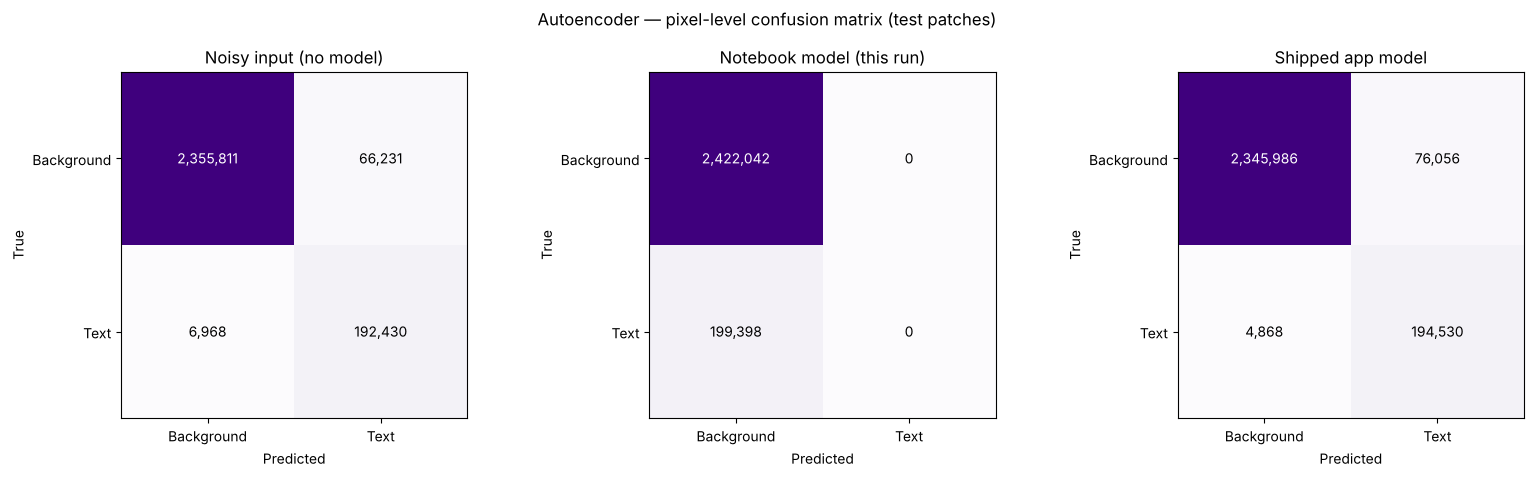

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a, (name, cm) in zip(ax, cms.items()):
    a.imshow(cm, cmap="Purples")
    a.set_xticks([0, 1]); a.set_xticklabels(["Background", "Text"]); a.set_yticks([0, 1]); a.set_yticklabels(["Background", "Text"])
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(name)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.suptitle("Autoencoder — pixel-level confusion matrix (test patches)"); plt.tight_layout(); plt.show()